# Garbage Classification (PyTorch)
## ขั้นตอนที่ 1: เช็คข้อมูล

In [1]:
import os
import hashlib
import torch
from torchvision import datasets
from torchvision.io import read_image, ImageReadMode

DATA_DIR = "garbage_classification"

# เช็คว่าใช้ GPU ของ Mac (MPS) ได้ไหม
device = "mps" if torch.backends.mps.is_available() else "cpu"
print("PyTorch version:", torch.__version__)
print("Device:", device)

PyTorch version: 2.14.1
Device: mps


In [2]:
# ImageFolder อ่านโฟลเดอร์ให้อัตโนมัติ: ชื่อโฟลเดอร์ย่อย = ชื่อคลาส
dataset = datasets.ImageFolder(DATA_DIR)

print("จำนวนรูปทั้งหมด:", len(dataset))
print("จำนวนคลาส:", len(dataset.classes))
print("รายชื่อคลาส:", dataset.classes)

จำนวนรูปทั้งหมด: 15515
จำนวนคลาส: 12
รายชื่อคลาส: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']


In [3]:
# นับจำนวนรูปในแต่ละคลาส
# dataset.targets = label (ตัวเลข) ของทุกรูป, torch.bincount นับว่าแต่ละเลขมีกี่ตัว
counts = torch.bincount(torch.tensor(dataset.targets))

for i, c in enumerate(dataset.classes):
    print(f"{i:2d} {c:15s} {counts[i].item():6d} รูป")

print("-" * 28)
print(f"   {'รวมทั้งหมด':15s} {counts.sum().item():6d} รูป")

 0 battery            945 รูป
 1 biological         985 รูป
 2 brown-glass        607 รูป
 3 cardboard          891 รูป
 4 clothes           5325 รูป
 5 green-glass        629 รูป
 6 metal              769 รูป
 7 paper             1050 รูป
 8 plastic            865 รูป
 9 shoes             1977 รูป
10 trash              697 รูป
11 white-glass        775 รูป
----------------------------
   รวมทั้งหมด       15515 รูป


## ขั้นตอนที่ 2: หารูปซ้ำและลบออก

โหลดทุกรูปเป็น tensor แล้วคำนวณ hash (MD5) จากค่า pixel ถ้า hash เท่ากันแปลว่าเป็นรูปเดียวกันเป๊ะ

In [4]:
# คำนวณ hash ของทุกรูป แล้วเก็บเป็น {hash: [รายชื่อไฟล์ที่มี hash นี้]}  (ใช้เวลาประมาณ 10-20 วินาที)
hash_dict = {}

for path, label in dataset.samples:
    img = read_image(path, mode=ImageReadMode.RGB)   # tensor ขนาด [3, H, W]
    h = hashlib.md5(img.numpy().tobytes()).hexdigest() + str(tuple(img.shape))
    if h not in hash_dict:
        hash_dict[h] = []
    hash_dict[h].append(path)

# เลือกเฉพาะ hash ที่มีมากกว่า 1 ไฟล์ = รูปซ้ำ
duplicates = [paths for paths in hash_dict.values() if len(paths) > 1]
print("พบรูปซ้ำทั้งหมด", len(duplicates), "กลุ่ม\n")
for paths in duplicates:
    print(paths)

พบรูปซ้ำทั้งหมด 18 กลุ่ม

['garbage_classification/clothes/clothes2051.jpg', 'garbage_classification/clothes/clothes5234.jpg']
['garbage_classification/green-glass/green-glass231.jpg', 'garbage_classification/green-glass/green-glass530.jpg']
['garbage_classification/green-glass/green-glass285.jpg', 'garbage_classification/green-glass/green-glass555.jpg']
['garbage_classification/green-glass/green-glass292.jpg', 'garbage_classification/green-glass/green-glass443.jpg']
['garbage_classification/green-glass/green-glass336.jpg', 'garbage_classification/green-glass/green-glass554.jpg']
['garbage_classification/green-glass/green-glass349.jpg', 'garbage_classification/green-glass/green-glass461.jpg']
['garbage_classification/green-glass/green-glass388.jpg', 'garbage_classification/green-glass/green-glass459.jpg']
['garbage_classification/green-glass/green-glass403.jpg', 'garbage_classification/green-glass/green-glass564.jpg']
['garbage_classification/green-glass/green-glass413.jpg', 'garbage_c

In [5]:
# แยกรายการไฟล์ที่จะลบ
# - ซ้ำในคลาสเดียวกัน   -> เก็บไว้ 1 รูป ลบที่เหลือ
# - ซ้ำข้ามคลาส (label ขัดกัน) -> ไม่รู้ว่าคลาสไหนถูก ลบทิ้งทั้งหมด
to_delete = []

for paths in duplicates:
    labels = set(p.split(os.sep)[-2] for p in paths)
    if len(labels) == 1:
        to_delete.extend(paths[1:])
    else:
        print("ซ้ำข้ามคลาส:", paths)
        to_delete.extend(paths)

print("\nจำนวนไฟล์ที่จะลบ:", len(to_delete))

ซ้ำข้ามคลาส: ['garbage_classification/metal/metal459.jpg', 'garbage_classification/white-glass/white-glass412.jpg']
ซ้ำข้ามคลาส: ['garbage_classification/plastic/plastic159.jpg', 'garbage_classification/white-glass/white-glass129.jpg']
ซ้ำข้ามคลาส: ['garbage_classification/plastic/plastic556.jpg', 'garbage_classification/white-glass/white-glass761.jpg']

จำนวนไฟล์ที่จะลบ: 22


In [6]:
# ลบไฟล์จริง (ย้อนกลับไม่ได้ ตรวจรายการด้านบนก่อนรัน)
for path in to_delete:
    os.remove(path)
    print("ลบแล้ว:", path)

print("\nลบเสร็จ", len(to_delete), "ไฟล์")

ลบแล้ว: garbage_classification/clothes/clothes5234.jpg
ลบแล้ว: garbage_classification/green-glass/green-glass530.jpg
ลบแล้ว: garbage_classification/green-glass/green-glass555.jpg
ลบแล้ว: garbage_classification/green-glass/green-glass443.jpg
ลบแล้ว: garbage_classification/green-glass/green-glass554.jpg
ลบแล้ว: garbage_classification/green-glass/green-glass461.jpg
ลบแล้ว: garbage_classification/green-glass/green-glass459.jpg
ลบแล้ว: garbage_classification/green-glass/green-glass564.jpg
ลบแล้ว: garbage_classification/green-glass/green-glass517.jpg
ลบแล้ว: garbage_classification/green-glass/green-glass563.jpg
ลบแล้ว: garbage_classification/green-glass/green-glass482.jpg
ลบแล้ว: garbage_classification/green-glass/green-glass561.jpg
ลบแล้ว: garbage_classification/green-glass/green-glass565.jpg
ลบแล้ว: garbage_classification/green-glass/green-glass544.jpg
ลบแล้ว: garbage_classification/green-glass/green-glass492.jpg
ลบแล้ว: garbage_classification/green-glass/green-glass592.jpg
ลบแล้ว: garbage

In [7]:
# โหลด dataset ใหม่หลังลบ แล้วนับอีกครั้ง
dataset = datasets.ImageFolder(DATA_DIR)
counts = torch.bincount(torch.tensor(dataset.targets))

for i, c in enumerate(dataset.classes):
    print(f"{i:2d} {c:15s} {counts[i].item():6d} รูป")

print("-" * 28)
print(f"   {'รวมทั้งหมด':15s} {counts.sum().item():6d} รูป")

 0 battery            945 รูป
 1 biological         985 รูป
 2 brown-glass        607 รูป
 3 cardboard          891 รูป
 4 clothes           5324 รูป
 5 green-glass        614 รูป
 6 metal              768 รูป
 7 paper             1050 รูป
 8 plastic            863 รูป
 9 shoes             1977 รูป
10 trash              697 รูป
11 white-glass        772 รูป
----------------------------
   รวมทั้งหมด       15493 รูป


## ขั้นตอนที่ 3: Undersample + แบ่งข้อมูล train / val / test (70 / 15 / 15)

1. **Undersample** คลาส clothes ให้เหลือ 1,500 รูป (สุ่มเลือก ไม่ได้ลบไฟล์จริง) เพื่อลดความไม่สมดุลและเทรนเร็วขึ้น
2. แบ่งเป็น **train** (เทรน + augmentation), **val** (เช็คผลระหว่างเทรน), **test** (วัดผลครั้งสุดท้าย)
3. ใช้ `stratify` ให้ทุกชุดมีสัดส่วนคลาสเท่ากัน
4. คัดลอกรูปไปไว้ในโฟลเดอร์ `garbage_split/train`, `garbage_split/val`, `garbage_split/test`

In [17]:
import random
from torchvision import transforms
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

IMG_SIZE = 224
BATCH_SIZE = 32
CLOTHES_LIMIT = 1500

# ค่า mean / std ของ ImageNet (ใช้คู่กับโมเดล pretrained)
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

# transform ของ train: augmentation = random resized crop, rotation, brightness/contrast
# RandomResizedCrop ครอปบางส่วนของรูปแล้ว resize เป็น 224x224 (ได้ทั้ง resize และ augmentation ในตัว)
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# transform ของ val / test: resize ด้านสั้นเป็น 256 แล้ว center crop 224x224
# (รักษาสัดส่วนรูป ไม่บีบให้เพี้ยน)
eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

In [18]:
# Undersample: สุ่มเก็บรูป clothes ไว้แค่ 1,500 รูป คลาสอื่นเก็บทั้งหมด
dataset = datasets.ImageFolder(DATA_DIR)
classes = dataset.classes
labels = dataset.targets

clothes_id = dataset.class_to_idx["clothes"]
clothes_idx = [i for i, y in enumerate(labels) if y == clothes_id]
other_idx = [i for i, y in enumerate(labels) if y != clothes_id]

random.seed(42)
clothes_keep = random.sample(clothes_idx, CLOTHES_LIMIT)
indices = sorted(other_idx + clothes_keep)

print("clothes ก่อน:", len(clothes_idx), "-> หลัง:", len(clothes_keep))
print("รูปทั้งหมด ก่อน:", len(labels), "-> หลัง:", len(indices))

clothes ก่อน: 5324 -> หลัง: 1500
รูปทั้งหมด ก่อน: 15493 -> หลัง: 11669


In [19]:
# แบ่ง index: 70% train, 30% เหลือ -> แบ่งครึ่งเป็น val 15%, test 15%
index_labels = [labels[i] for i in indices]
train_idx, temp_idx = train_test_split(
    indices, test_size=0.30, stratify=index_labels, random_state=42
)
temp_labels = [labels[i] for i in temp_idx]
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, stratify=temp_labels, random_state=42
)

print("train:", len(train_idx))
print("val  :", len(val_idx))
print("test :", len(test_idx))
print("รวม  :", len(train_idx) + len(val_idx) + len(test_idx))

train: 8168
val  : 1750
test : 1751
รวม  : 11669


In [20]:
# คัดลอกรูปไปไว้ในโฟลเดอร์ใหม่ แยกตาม train / val / test และคลาส
#   garbage_split/
#     train/battery/..., train/biological/..., ...
#     val/...
#     test/...
# (คัดลอก ไม่ใช่ย้าย -> โฟลเดอร์ garbage_classification เดิมยังอยู่ครบ)
import shutil

SPLIT_DIR = "garbage_split"

# ถ้าเคยสร้างไว้แล้ว ลบของเก่าก่อน จะได้ไม่มีรูปค้างจากการรันครั้งก่อน
if os.path.exists(SPLIT_DIR):
    shutil.rmtree(SPLIT_DIR)

for split_name, split_idx in [("train", train_idx), ("val", val_idx), ("test", test_idx)]:
    for i in split_idx:
        path, label = dataset.samples[i]
        dst_folder = os.path.join(SPLIT_DIR, split_name, classes[label])
        os.makedirs(dst_folder, exist_ok=True)
        shutil.copy(path, dst_folder)
    print(f"{split_name}: คัดลอก {len(split_idx)} รูป -> {os.path.join(SPLIT_DIR, split_name)}")

train: คัดลอก 8168 รูป -> garbage_split/train
val: คัดลอก 1750 รูป -> garbage_split/val
test: คัดลอก 1751 รูป -> garbage_split/test


In [21]:
# โหลดแต่ละโฟลเดอร์ด้วย ImageFolder (train ใช้ train_transform, val/test ใช้ eval_transform)
# ครั้งต่อไปถ้ามีโฟลเดอร์ garbage_split แล้ว รันแค่ cell นี้ได้เลย ไม่ต้อง undersample / split ใหม่
train_set = datasets.ImageFolder(os.path.join(SPLIT_DIR, "train"), transform=train_transform)
val_set = datasets.ImageFolder(os.path.join(SPLIT_DIR, "val"), transform=eval_transform)
test_set = datasets.ImageFolder(os.path.join(SPLIT_DIR, "test"), transform=eval_transform)

print("คลาสตรงกันทุกชุด:", train_set.classes == val_set.classes == test_set.classes == classes)

# นับจำนวนรูปของแต่ละคลาสในแต่ละโฟลเดอร์
train_counts = torch.bincount(torch.tensor(train_set.targets), minlength=len(classes))
val_counts = torch.bincount(torch.tensor(val_set.targets), minlength=len(classes))
test_counts = torch.bincount(torch.tensor(test_set.targets), minlength=len(classes))

print(f"\n{'class':15s} {'train':>6s} {'val':>6s} {'test':>6s}")
for i, c in enumerate(classes):
    print(f"{c:15s} {train_counts[i].item():6d} {val_counts[i].item():6d} {test_counts[i].item():6d}")
print("-" * 36)
print(f"{'รวม':15s} {train_counts.sum().item():6d} {val_counts.sum().item():6d} {test_counts.sum().item():6d}")

คลาสตรงกันทุกชุด: True

class            train    val   test
battery            661    142    142
biological         689    148    148
brown-glass        425     91     91
cardboard          624    133    134
clothes           1050    225    225
green-glass        430     92     92
metal              538    115    115
paper              735    157    158
plastic            604    130    129
shoes             1384    296    297
trash              488    105    104
white-glass        540    116    116
------------------------------------
รวม               8168   1750   1751


In [22]:
# DataLoader: แบ่งข้อมูลเป็น batch ละ 32 รูป (train สุ่มลำดับทุก epoch)
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)

print("จำนวน batch -> train:", len(train_loader), "| val:", len(val_loader), "| test:", len(test_loader))

# ลองดึงมา 1 batch เพื่อเช็คขนาด
images, targets = next(iter(train_loader))
print("images:", images.shape)   # [batch, channel, height, width]
print("labels:", targets.shape)

จำนวน batch -> train: 256 | val: 55 | test: 55
images: torch.Size([32, 3, 224, 224])
labels: torch.Size([32])


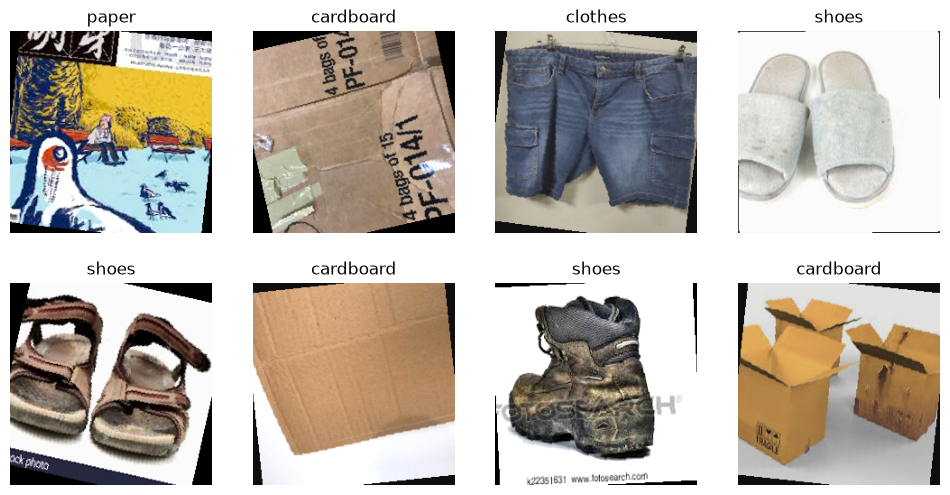

In [14]:
# แสดงตัวอย่างรูปจาก train (หลัง augmentation)
plt.figure(figsize=(12, 6))
for i in range(8):
    img = images[i].permute(1, 2, 0)                          # [C,H,W] -> [H,W,C]
    img = img * torch.tensor(STD) + torch.tensor(MEAN)        # ย้อน normalize กลับ
    img = img.clamp(0, 1)
    plt.subplot(2, 4, i + 1)
    plt.imshow(img)
    plt.title(classes[targets[i]])
    plt.axis("off")
plt.show()

### Focal Loss (เตรียมไว้ใช้ตอนเทรนในขั้นที่ 4)

Focal Loss = Cross Entropy × (1 − p)<sup>γ</sup>

- `p` = ความมั่นใจของโมเดลในคลาสที่ถูก
- รูปที่ง่าย (p สูง) → loss ถูกลดลงมาก
- รูปที่ยาก (p ต่ำ) → loss แทบไม่ถูกลด โมเดลจึงโฟกัสกับรูปที่จำแนกยาก
- `gamma = 0` จะเท่ากับ Cross Entropy ปกติ, นิยมใช้ `gamma = 2`

In [15]:
import torch.nn as nn
import torch.nn.functional as F

class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0):
        super().__init__()
        self.gamma = gamma

    def forward(self, logits, targets):
        ce = F.cross_entropy(logits, targets, reduction="none")  # loss ของแต่ละรูป
        p = torch.exp(-ce)                                        # ความมั่นใจในคลาสที่ถูก
        focal = (1 - p) ** self.gamma * ce
        return focal.mean()

criterion = FocalLoss(gamma=2.0)

In [16]:
# ทดสอบ: เทียบ Cross Entropy กับ Focal Loss บนรูปง่าย vs รูปยาก (คลาสที่ถูก = 0)
easy = torch.tensor([[5.0, 0.0, 0.0]])   # โมเดลมั่นใจมากว่าเป็นคลาส 0
hard = torch.tensor([[0.5, 0.0, 0.0]])   # โมเดลไม่ค่อยมั่นใจ
target = torch.tensor([0])

for name, logits in [("รูปง่าย", easy), ("รูปยาก", hard)]:
    ce = F.cross_entropy(logits, target).item()
    fl = criterion(logits, target).item()
    print(f"{name}: CrossEntropy = {ce:.6f} | FocalLoss = {fl:.6f} | เหลือ {fl / ce * 100:.2f}% ของ CE")

รูปง่าย: CrossEntropy = 0.013386 | FocalLoss = 0.000002 | เหลือ 0.02% ของ CE
รูปยาก: CrossEntropy = 0.794377 | FocalLoss = 0.238674 | เหลือ 30.05% ของ CE
